# 01 – Data overview

First look at the raw OTTO file: how the data is structured and how big it is.

- Look at a few sessions to understand the JSON format
- Count sessions and events in the full file
- Save the totals so later notebooks don't have to read the 11 GB file again

In [1]:
import json
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

RAW_FILE = Path("../data/raw/otto-recsys-train.jsonl")
OUT_DIR = Path("../data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. What does one session look like?

Each line in the file is one session: a session id and a list of events.
Reading only the first 1,000 lines is enough to see the structure.

In [2]:
sample = pd.read_json(RAW_FILE, lines=True, nrows=1000)
print(sample.shape)
sample.head()

(1000, 2)


,session,events
0,0,"[{'aid': 1517085, 'ts': 1659304800025, 'type':..."
1,1,"[{'aid': 424964, 'ts': 1659304800025, 'type': ..."
2,2,"[{'aid': 763743, 'ts': 1659304800038, 'type': ..."
3,3,"[{'aid': 1425967, 'ts': 1659304800095, 'type':..."
4,4,"[{'aid': 613619, 'ts': 1659304800119, 'type': ..."


In [3]:
# events of the first session as a table
first_session = pd.DataFrame(sample.loc[0, "events"])
first_session["time"] = pd.to_datetime(first_session["ts"], unit="ms", utc=True).dt.tz_convert("Europe/Berlin")
first_session.head(15)

,aid,ts,type,time
0,1517085,1659304800025,clicks,2022-08-01 00:00:00.025000+02:00
1,1563459,1659304904511,clicks,2022-08-01 00:01:44.511000+02:00
2,1309446,1659367439426,clicks,2022-08-01 17:23:59.426000+02:00
3,16246,1659367719997,clicks,2022-08-01 17:28:39.997000+02:00
4,1781822,1659367871344,clicks,2022-08-01 17:31:11.344000+02:00
5,1152674,1659367885796,clicks,2022-08-01 17:31:25.796000+02:00
6,1649869,1659369893840,carts,2022-08-01 18:04:53.840000+02:00
7,461689,1659369898050,carts,2022-08-01 18:04:58.050000+02:00
8,305831,1659370027105,orders,2022-08-01 18:07:07.105000+02:00
9,461689,1659370027105,orders,2022-08-01 18:07:07.105000+02:00


`aid` is the product, `ts` is the time in milliseconds, `type` is clicks / carts / orders.
The same product can show up several times in one session (clicked again later, added to cart, ordered).

In [4]:
# how many events per session in these 1,000 sessions
sample["n_events"] = sample["events"].str.len()
sample["n_events"].describe()

count    1000.00000
mean       80.26700
std        94.87775
min         2.00000
25%        11.00000
50%        41.00000
75%       115.00000
max       482.00000
Name: n_events, dtype: float64

## 2. Count the full file

The file is too big to load into pandas at once, so it's read line by line.
This takes around 10–15 minutes.

In [5]:
n_sessions = 0
event_counts = {"clicks": 0, "carts": 0, "orders": 0}
sessions_with = {"clicks": 0, "carts": 0, "orders": 0}  # sessions that have this type at least once
length_counts = {}  # events per session -> number of sessions
first_ts = None
last_ts = None

with open(RAW_FILE, encoding="utf-8") as f:
    for line in f:
        events = json.loads(line)["events"]
        n_sessions += 1

        length = len(events)
        length_counts[length] = length_counts.get(length, 0) + 1

        types_seen = set()
        for e in events:
            event_counts[e["type"]] += 1
            types_seen.add(e["type"])
        for t in types_seen:
            sessions_with[t] += 1

        # events in a session are sorted by time, so first/last give the range
        if first_ts is None or events[0]["ts"] < first_ts:
            first_ts = events[0]["ts"]
        if last_ts is None or events[-1]["ts"] > last_ts:
            last_ts = events[-1]["ts"]

        if n_sessions % 1_000_000 == 0:
            print(f"{n_sessions:,} sessions done")

print(f"Done: {n_sessions:,} sessions")

1,000,000 sessions done
2,000,000 sessions done
3,000,000 sessions done
4,000,000 sessions done
5,000,000 sessions done
6,000,000 sessions done
7,000,000 sessions done
8,000,000 sessions done
9,000,000 sessions done
10,000,000 sessions done
11,000,000 sessions done
12,000,000 sessions done
Done: 12,899,779 sessions


In [6]:
summary = pd.DataFrame({
    "event_type": list(event_counts.keys()),
    "events": list(event_counts.values()),
    "sessions_with_type": list(sessions_with.values()),
})
summary["share_of_events_%"] = (summary["events"] / summary["events"].sum() * 100).round(2)
summary["share_of_sessions_%"] = (summary["sessions_with_type"] / n_sessions * 100).round(2)

start = pd.to_datetime(first_ts, unit="ms", utc=True).tz_convert("Europe/Berlin")
end = pd.to_datetime(last_ts, unit="ms", utc=True).tz_convert("Europe/Berlin")

print(f"Sessions: {n_sessions:,}")
print(f"Events:   {summary['events'].sum():,}")
print(f"From {start} to {end}")
summary

Sessions: 12,899,779
Events:   216,716,096
From 2022-08-01 00:00:00.025000+02:00 to 2022-08-28 23:59:59.984000+02:00


,event_type,events,sessions_with_type,share_of_events_%,share_of_sessions_%
0,clicks,194720954,12899779,89.85,100.00
1,carts,16896191,3810706,7.80,29.54
2,orders,5098951,1626338,2.35,12.61


In [7]:
# save so we don't need to read the big file again
summary.to_csv(OUT_DIR / "population_summary.csv", index=False)

lengths = pd.DataFrame(sorted(length_counts.items()), columns=["events_per_session", "sessions"])
lengths.to_csv(OUT_DIR / "session_lengths.csv", index=False)

## 3. Charts

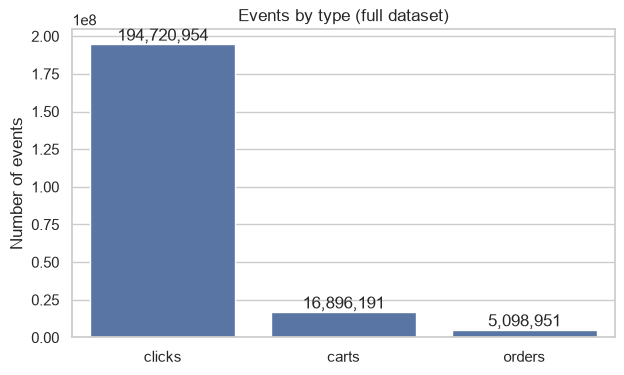

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=summary, x="event_type", y="events", ax=ax)
ax.set_title("Events by type (full dataset)")
ax.set_xlabel("")
ax.set_ylabel("Number of events")
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")
plt.show()

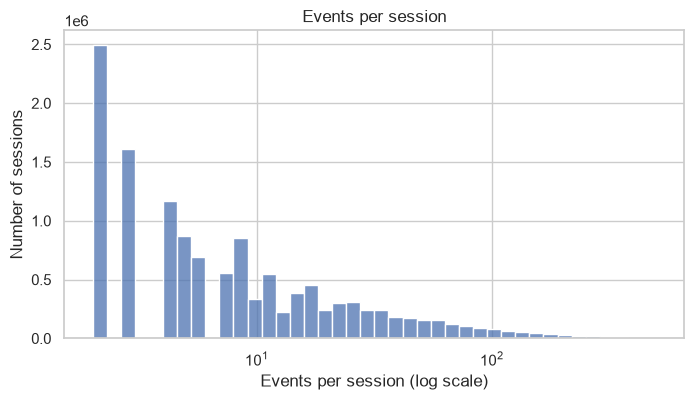

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=lengths, x="events_per_session", weights="sessions", bins=40, log_scale=True, ax=ax)
ax.set_title("Events per session")
ax.set_xlabel("Events per session (log scale)")
ax.set_ylabel("Number of sessions")
plt.show()